# Paper 23: Masked Autoencoders Are Scalable Vision Learners (MAE)
**Authors**: Kaiming He, Xinlei Chen, Saining Xie, Yanghao Li, Piotr Bojanowski, Ross Girshick (Facebook AI Research, CVPR 2022)

---

## 1. The Historical Breaking Point: Why BERT Masking Failed on Vision
In NLP, Masked Language Modeling (BERT) masks 15% of tokens. But masking 15% of image patches yields trivial local pixel interpolation because images have **heavy spatial redundancy**. Furthermore, CNNs cannot skip masked patches without breaking 2D spatial convolution grids.

## 2. The Thought Experiment: Asymmetric Masking at 75%
Kaiming He et al. discovered that vision requires a radically higher masking ratio and an asymmetric design:
1. **High Masking Ratio (75%–80%)**: Removes redundant pixel correlations, forcing the model to learn 3D scene semantics.
2. **Asymmetric Architecture**:
   - **Deep Encoder**: Operates **strictly on the 25% visible patches**! Masked patches are completely discarded, yielding a **$16\times$ compute speedup**!
   - **Lightweight Decoder**: Takes encoded visible tokens + learnable `[MASK]` tokens and reconstructs normalized pixel values.
3. **MSE Loss on Masked Patches**: Model is supervised strictly on reconstructing the hidden 75% patches.

In this notebook, you will explore:
1. `patchify` and `random_masking` mechanics
2. Visualizing masked images at 75% removal
3. Training `MaskedAutoencoderViT` and reconstructing missing visual content

---
## Setup & Autoreload

In [1]:
%load_ext autoreload
%autoreload 2

import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from model import (
    patchify,
    unpatchify,
    random_masking,
    MaskedAutoencoderViT,
)

print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1+cpu


---
## 1. Visualizing 75% Random Masking
Let's see what an image looks like when 75% of its patches are masked out. Notice how challenging the task is—you can barely recognize the underlying shapes!

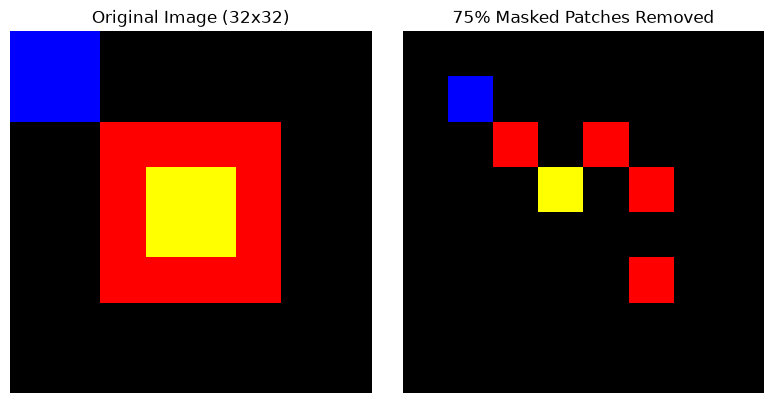

In [2]:
torch.manual_seed(42)
# Create a synthetic colored geometric pattern
img = torch.zeros(1, 3, 32, 32)
img[:, 0, 8:24, 8:24] = 1.0  # Red square
img[:, 1, 12:20, 12:20] = 1.0  # Green center
img[:, 2, :8, :8] = 1.0  # Blue corner

patch_size = 4
patches = patchify(img, patch_size)  # (1, 64, 48)
x_masked, mask, ids_restore = random_masking(patches, mask_ratio=0.75)

# Construct masked visualization (replace masked patches with zeros)
mask_expanded = mask.unsqueeze(-1).repeat(1, 1, patch_size * patch_size * 3)
masked_patches = patches * (1 - mask_expanded)
masked_img = unpatchify(masked_patches, patch_size)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(img[0].permute(1, 2, 0).numpy())
axes[0].set_title("Original Image (32x32)")
axes[0].axis("off")

axes[1].imshow(masked_img[0].permute(1, 2, 0).numpy())
axes[1].set_title("75% Masked Patches Removed")
axes[1].axis("off")

plt.tight_layout()
plt.show()

---
## 2. Training Masked Autoencoder
We train `MaskedAutoencoderViT` on our synthetic image to reconstruct the missing 75% patches using MSE loss.

Training MAE on 75% masked reconstruction...
Initial Loss: 0.6775 -> Final Loss: 0.0723


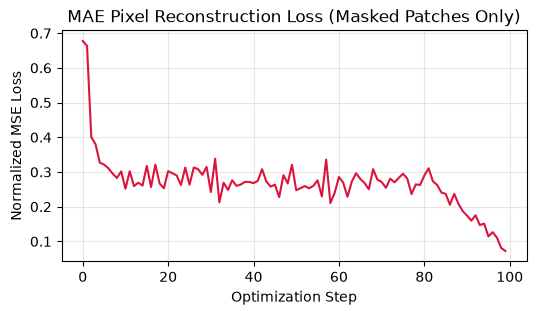

In [3]:
torch.manual_seed(42)
mae = MaskedAutoencoderViT(
    img_size=32,
    patch_size=4,
    in_chans=3,
    embed_dim=64,
    depth=3,
    num_heads=4,
    decoder_embed_dim=32,
    decoder_depth=2,
    decoder_num_heads=2,
    norm_pix_loss=True,
)

optimizer = torch.optim.AdamW(mae.parameters(), lr=2e-3, weight_decay=1e-4)

losses = []
print("Training MAE on 75% masked reconstruction...")
for step in range(100):
    optimizer.zero_grad()
    loss, pred, mask = mae(img, mask_ratio=0.75)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

print(f"Initial Loss: {losses[0]:.4f} -> Final Loss: {losses[-1]:.4f}")

plt.figure(figsize=(6, 3))
plt.plot(losses, color="crimson")
plt.title("MAE Pixel Reconstruction Loss (Masked Patches Only)")
plt.xlabel("Optimization Step")
plt.ylabel("Normalized MSE Loss")
plt.grid(True, alpha=0.3)
plt.show()

---
## 3. Visualizing Reconstructed Images: Original vs. Masked vs. Reconstructed
Let's reconstruct the full image by pasting the model's predictions into the masked patches while keeping the visible patches intact!

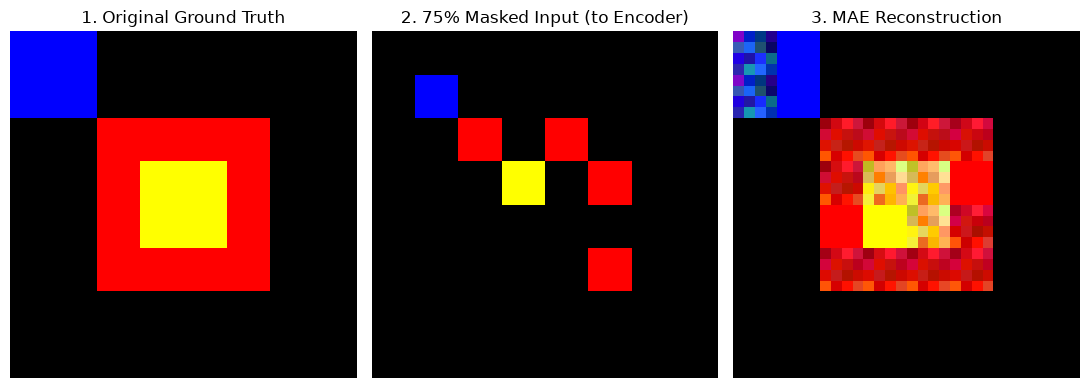

In [4]:
mae.eval()
with torch.no_grad():
    loss, pred, mask = mae(img, mask_ratio=0.75)

    # If norm_pix_loss was used, un-normalize target patch predictions
    target_patches = patchify(img, patch_size=4)
    mean = target_patches.mean(dim=-1, keepdim=True)
    var = target_patches.var(dim=-1, keepdim=True)
    pred_unnorm = pred * (var + 1e-6) ** 0.5 + mean

    # Combine visible patches with model's predicted masked patches
    mask_exp = mask.unsqueeze(-1).repeat(1, 1, 4 * 4 * 3)
    composed_patches = target_patches * (1 - mask_exp) + pred_unnorm * mask_exp
    reconstruction = unpatchify(composed_patches, patch_size=4).clamp(0, 1)

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(img[0].permute(1, 2, 0).numpy())
axes[0].set_title("1. Original Ground Truth")
axes[0].axis("off")

axes[1].imshow(masked_img[0].permute(1, 2, 0).numpy())
axes[1].set_title("2. 75% Masked Input (to Encoder)")
axes[1].axis("off")

axes[2].imshow(reconstruction[0].permute(1, 2, 0).numpy())
axes[2].set_title("3. MAE Reconstruction")
axes[2].axis("off")

plt.tight_layout()
plt.show()